# Exercise 1: Data Gathering and Exploratory Analysis

The session collects the apartments for sale on Skopje Flats, a listings portal, and describes them without modelling them. The portal is a stored snapshot in `data/site`, and the notebook serves it from this machine, so every request stays on the local loopback address. The listings are synthetic and describe no real apartment, seller, or agency.

The notebook has two parts:

- Part 1 gathers the listings. It reads one page and turns each listing into a record, follows the pages to the last one, collects a page that a browser has to render and a paged endpoint, and joins the sources into one data frame.
- Part 2 describes that data frame. It classifies the columns, examines what is missing, and summarizes each column and each relationship with statistics and figures.

## Setup

In [1]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright

DATA = Path("data")

In [2]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [3]:
# The statistics endpoint answers /api/listing-stats?page=N from a stored file,
# and every other path is a file under data/site.
STATS = json.loads((DATA / "api" / "listing-stats.json").read_text(encoding="utf-8"))
STATS_PER_PAGE = 50


class Portal(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def do_GET(self) -> None:
        url = urlparse(self.path)
        if url.path != "/api/listing-stats":
            return super().do_GET()
        page = int(parse_qs(url.query).get("page", ["1"])[0])
        start = (page - 1) * STATS_PER_PAGE
        body = json.dumps(
            {
                "total": len(STATS),
                "page": page,
                "per_page": STATS_PER_PAGE,
                "results": STATS[start : start + STATS_PER_PAGE],
            }
        ).encode()
        self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Portal, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:50954/'

## Part 1: Gathering the Listings

The portal offers the listings in three forms: pages of static markup, a page that a script fills in after it loads, and an endpoint that returns JSON. Each form needs its own collection technique, and the last section of this part joins what they return.

### 1. Requests and Responses

A request names a resource by its URL, and the response carries a status code, headers, and a body. The `timeout` argument bounds how long the client waits, so a server that never answers raises an error instead of stalling the notebook.

The status code is read first, because a body that arrives with an error code is an error page rather than the data. A code in the 200s means success, a code in the 400s means the request was at fault, such as a request for a page that does not exist, and a code in the 500s means the server failed.

In [4]:
response = requests.get(urljoin(BASE, "listings/page-1.html"), timeout=10)
print(response.content[:100])

response.status_code
print("Reponse status code: ", response.status_code)

b'<!doctype html>\r\n<html lang="en">\r\n<head>\r\n<meta charset="utf-8">\r\n<meta name="viewport" content="wi'
Reponse status code:  200


`raise_for_status()` turns a code in the 400s or the 500s into an exception, so the code after it only ever sees a successful response. The headers describe the body, and `Content-Type` names its format and its character encoding. `response.content` holds the body as bytes, and `response.text` decodes it into a string.

In [5]:
response.raise_for_status()


response.headers["Content-Type"], len(response.content)
print("Content-Type header:", response.headers["Content-Type"])
print("Response length:", len(response.content))

Content-Type header: text/html; charset=utf-8
Response length: 17476


In [6]:
print("Response text:\n", response.text)

Response text:
 <!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Apartments for sale in Skopje, page 1 | Skopje Flats</title>
<link rel="stylesheet" href="../assets/site.css">
</head>
<body>
<header class="site-header">
<div class="wrap">
<a class="brand" href="../index.html"><img src="../assets/logo.svg" alt="" width="32" height="32">Skopje Flats</a>
<nav class="primary-nav" aria-label="Main"><a href="../listings/page-1.html" aria-current="page">Buy</a><a href="#">Rent</a><a href="#" class="extra">New homes</a><a href="#" class="extra">Agents</a><a href="../market-index.html">Market index</a></nav>
<div class="account"><a class="saved" href="#">Saved</a><a class="button" href="#">Post a listing</a></div>
</div>
</header>
<main>
<div class="wrap">
<ol class="breadcrumb"><li><a href="../index.html">Home</a></li><li><a href="page-1.html">Buy</a></li><li aria-current="page">Apartments in Skopje</li><

A page that does not exist still returns a response. Its status code says so, and `raise_for_status()` turns that code into an exception.

In [7]:
missing = requests.get(urljoin(BASE, "listings/page-99.html"), timeout=10)
print(missing.status_code, missing.ok)
try:
    missing.raise_for_status()
except requests.HTTPError as error:
    print(error)

#Moj kod:
moved = requests.get(urljoin(BASE, "listings/pages/page-1.html"), timeout=10)    
print(moved.status_code, moved.ok)

try: moved.raise_for_status()
except requests.HTTPError as error: print(error)

404 False
404 Client Error: File not found for url: http://127.0.0.1:50954/listings/page-99.html
404 False
404 Client Error: File not found for url: http://127.0.0.1:50954/listings/pages/page-1.html


### 2. Selectors

Beautiful Soup parses the markup into a tree of elements, and a CSS selector picks elements out of that tree. `select()` returns every match, and `select_one()` returns the first match.

Four kinds of selector cover most pages:

- a tag selector, such as `h2`, matches by element name,
- a class selector, such as `.price`, matches by the `class` attribute,
- an identifier selector, such as `#listing-2563`, matches by the `id` attribute, which is unique within a page, and
- a descendant selector, such as `ul.features li`, matches the elements on the right that lie anywhere inside an element on the left.

A tag and a class written together, as in `article.listing`, match an element that satisfies both. Each listing on the page is such an element.

In [8]:
# print("Response text:\n", response.text)

soup = BeautifulSoup(response.text, "lxml")
cards = soup.select("article.listing")
# print("Cards: ", cards)

first = cards[0]
len(cards), first["data-id"]

#Moj kod:
print("Amount of cards: ", len(cards)) 
print("First card data-id: ", first["data-id"])

card_h2 = soup.select("article.listing h2.title")

first_card_get_text = card_h2[0].get_text()
print("First card get text: ", first_card_get_text)

cards_titles = [title.get_text() for title in card_h2]
print("Card titles: ", cards_titles)

first_card_price = first.select_one("p.price").get_text()
print("First card price: ", first_card_price)

card_prices = soup.select("article.listing p.price")
prices =[p.get_text() for p in card_prices]  
print("Card Prices: ", prices)

Amount of cards:  12
First card data-id:  2563
First card get text:  3-room apartment in Гази Баба
Card titles:  ['3-room apartment in Гази Баба', '1-room apartment in Чаир', '1-room apartment in Аеродром', '3-room apartment in Карпош', '4-room apartment in Карпош', '2-room apartment in Карпош', '3-room apartment in Гази Баба', '3-room apartment in Гази Баба', '2-room apartment in Аеродром', '3-room apartment in Аеродром', '3-room apartment in Центар', '2-room apartment in Бутел']
First card price:  Price: 72 000 EUR
Card Prices:  ['Price: 72 000 EUR', 'Price: 42 000 EUR', 'Price: 55 500 EUR', 'Price: 90 500 EUR', 'Price: 206 500 EUR', 'Price: 96 000 EUR', 'Price: 131 500 EUR', 'Price: 100 000 EUR', 'Price: 92 500 EUR', 'Price: 162 000 EUR', 'Price: 127 000 EUR', 'Price: 2 990 000 MKD']


An element carries text and attributes. Indexing an element, as in `first["data-id"]`, reads an attribute, and `get_text()` reads the text inside it.

A selector can match more than intended. The page has more `h2` headings than listings, because its other sections have headings too, and the descendant selector `article.listing h2` keeps only the headings inside a listing.

In [9]:
{
    "h2": len(soup.select("h2")),
    "article.listing h2": len(soup.select("article.listing h2")),
    "#listing-" + first["data-id"]: len(soup.select(f"#listing-{first['data-id']}")),
    "ul.features li": len(soup.select("ul.features li")),
}

{'h2': 17, 'article.listing h2': 12, '#listing-2563': 1, 'ul.features li': 35}

Each listing shows up to three features, which are the rooms, the condition, and the elevator, so twelve listings could hold 36 of them. Counting each feature class shows which one is absent from some listing.

In [10]:
{
    selector: len(soup.select(selector))
    for selector in [".rooms", ".condition", ".elevator", ".balcony"]
}

{'.rooms': 12, '.condition': 11, '.elevator': 12, '.balcony': 0}

An empty match is a normal outcome. `select()` returns an empty list and `select_one()` returns `None`, so the code checks for `None` before it reads an element that may be absent.

In [11]:
first.select_one(".balcony") is None

True

### 3. One Record per Element

Each listing becomes one record, and the text and the attributes of its elements become the fields. The fields are of two kinds:

- a required field, such as the price, is present in every listing, so its absence means the page has changed and the parser raises an error, and
- an optional field, such as the condition, may be absent, and an absent element becomes a missing value.

The price and the summary hold their numbers inside a sentence.

In [12]:
print(first.select_one(".price").get_text())
print(first.select_one(".summary").get_text())

Price: 72 000 EUR
A 73 m² apartment on floor 6 of 8, built in 1958.


A regular expression reads those numbers out. The patterns below use these constructs:

- `\d` matches one digit, and `\d{4}` matches exactly four,
- `[\d ]*` matches any run of digits and spaces, because the price uses a space to separate thousands,
- `[\d.]+` matches one or more digits and points, which covers an area with a decimal part,
- `(EUR|MKD)` matches either currency, and
- each pair of parentheses captures the text it matches, and `groups()` returns the captures in order.

`search()` returns `None` when the pattern does not match, so the helper `captures` checks for it just as `required_text` checks for an absent element.

In [13]:
PRICE_REGEX = re.compile(r"(\d[\d ]*) (EUR|MKD)")
SUMMARY_REGEX = re.compile(
    r"([\d.]+) m² apartment on floor (\d+) of (\d+), built in (\d{4})"
)


def required_text(card: Tag, selector: str) -> str:
    element = card.select_one(selector)
    if element is None:
        raise ValueError(f"Listing {card['data-id']} has no {selector} element.")
    return element.get_text(strip=True)


def optional_text(card: Tag, selector: str) -> str | None:
    element = card.select_one(selector)
    return element.get_text(strip=True) if element else None


def captures(pattern: re.Pattern[str], text: str) -> tuple[str, ...]:
    match = pattern.search(text)
    if match is None:
        raise ValueError(f"{text!r} does not match {pattern.pattern!r}.")
    return match.groups()


def parse_listing(card: Tag) -> dict[str, object]:
    amount, currency = captures(PRICE_REGEX, required_text(card, ".price"))
    area, floor, floors, year = captures(SUMMARY_REGEX, required_text(card, ".summary"))
    elevator = optional_text(card, ".elevator")

    # print("Amount: ", amount)
    # print("Currency: ", currency)

    return {
        "listing_id": int(card["data-id"]),
        "municipality": required_text(card, ".title").split(" in ")[-1],
        "price": int(amount.replace(" ", "")),
        "currency": currency,
        "area": float(area),
        "rooms": int(required_text(card, ".rooms").split()[0]),
        "floor": int(floor),
        "floors": int(floors),
        "year_built": int(year),
        "condition": optional_text(card, ".condition"),
        "elevator": None if elevator is None else elevator.endswith("yes"),
    }


parse_listing(first)

{'listing_id': 2563,
 'municipality': 'Гази Баба',
 'price': 72000,
 'currency': 'EUR',
 'area': 73.0,
 'rooms': 3,
 'floor': 6,
 'floors': 8,
 'year_built': 1958,
 'condition': 'good',
 'elevator': True}

The other fields are read with plain string methods:

- the municipality is the text after the last " in " of a title such as "3-room apartment in Гази Баба",
- the room count is the first word of a feature such as "3 rooms", and
- the elevator is `True` when its feature reads "Elevator: yes", `False` when it reads "Elevator: no", and missing when the feature is absent.

### 4. Pagination

The listings span several pages, and each page except the last links to the next one. The scraper follows that link until a page has none. `urljoin()` resolves the link, which is relative to the current page, into a full URL. Each page adds its records to one list, and the list becomes a data frame at the end.

In [14]:
records, url, pages = [], urljoin(BASE, "listings/page-1.html"), 0
while url:
    page = requests.get(url, timeout=10)
    page.raise_for_status()
    soup = BeautifulSoup(page.text, "lxml")

    #Za sekoja strana se sobiraat novi records
    records += [parse_listing(card) for card in soup.select("article.listing")]

    link = soup.select_one("a.next")
    #Koga ke e None, zavrhuva loopot
    url = urljoin(url, link["href"]) if link else None 
    pages += 1

listings = pd.DataFrame(records)
print(listings)

pages, listings.shape
print("Pages: ", pages)
print("Listings shape: ", listings.shape)

     listing_id municipality    price currency   area  rooms  floor  floors  \
0          2563    Гази Баба    72000      EUR   73.0      3      6       8   
1          4159         Чаир    42000      EUR   38.0      1      1      10   
2          6002     Аеродром    55500      EUR   41.4      1      5       8   
3          7035       Карпош    90500      EUR   75.0      3      3       4   
4          1836       Карпош   206500      EUR  110.0      4      4       6   
..          ...          ...      ...      ...    ...    ...    ...     ...   
175        3400    Гази Баба  4960000      MKD   67.0      2      5       7   
176        4969       Карпош   167000      EUR  106.0      4      4       5   
177        6704     Аеродром   125000      EUR   93.0      4      6       7   
178        1536        Бутел    69500      EUR   63.3      2      1       8   
179        5238    Гази Баба  6600000      MKD  108.3      4      6       8   

     year_built         condition elevator  
0     

In [15]:
listings.head()

,listing_id,municipality,price,currency,area,rooms,floor,floors,year_built,condition,elevator
0,2563,Гази Баба,72000,EUR,73.0,3,6,8,1958,good,True
1,4159,Чаир,42000,EUR,38.0,1,1,10,2021,renovated,True
2,6002,Аеродром,55500,EUR,41.4,1,5,8,2011,needs renovation,True
3,7035,Карпош,90500,EUR,75.0,3,3,4,1964,needs renovation,False
4,1836,Карпош,206500,EUR,110.0,4,4,6,2008,renovated,True


### 5. A Page That Renders Itself

The market index page builds its table with a script after it loads. The markup that `requests` receives holds only the empty table, because `requests` downloads the markup and runs no script.

In [16]:
static = BeautifulSoup(
    requests.get(urljoin(BASE, "market-index.html"), timeout=10).text, "lxml"
)
print("static: \n", static)

table_row = len(static.select("#index tr"))
print("table row: ", table_row) #Bidejki tabelata e geneirana so JS, nema da ima rows, pa zatoa 0.

static: 
 <!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8"/>
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<title>Market index | Skopje Flats</title>
<link href="assets/site.css" rel="stylesheet"/>
</head>
<body>
<header class="site-header">
<div class="wrap">
<a class="brand" href="index.html"><img alt="" height="32" src="assets/logo.svg" width="32"/>Skopje Flats</a>
<nav aria-label="Main" class="primary-nav"><a href="listings/page-1.html">Buy</a><a href="#">Rent</a><a class="extra" href="#">New homes</a><a class="extra" href="#">Agents</a><a aria-current="page" href="market-index.html">Market index</a></nav>
<div class="account"><a class="saved" href="#">Saved</a><a class="button" href="#">Post a listing</a></div>
</div>
</header>
<main>
<div class="wrap">
<ol class="breadcrumb"><li><a href="index.html">Home</a></li><li aria-current="page">Market index</li></ol>
<div class="page-head"><h1>Market index</h1><p>The mean asking price per square metre,

A browser driven by Playwright runs the script. The table appears some time after the page loads, so the browser waits until a table cell exists before it reads the markup. The notebook already runs an event loop, so it uses the asynchronous interface of Playwright and awaits each step.

The rendered table starts with a header row of `th` cells, and the selector `tr:has(td)` keeps only the rows that contain data cells.

In [17]:
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    tab = await browser.new_page()
    await tab.goto(urljoin(BASE, "market-index.html"))
    await tab.wait_for_selector("#index td")
    rendered = await tab.content()
    await browser.close()

rows = BeautifulSoup(rendered, "lxml").select("#index tr:has(td)")
market_index = pd.DataFrame(
    [
        {
            "municipality": row.select_one(".municipality").get_text(),
            "portal_eur_per_m2": int(row.select_one(".eur-per-m2").get_text()),
        }
        for row in rows
    ]
)
print("market_index: ", market_index)

market_index:     municipality  portal_eur_per_m2
0        Центар               1977
1        Карпош               1916
2      Аеродром               1530
3   Кисела Вода               1330
4     Гази Баба               1218
5  Ѓорче Петров               1064
6          Чаир               1092
7         Бутел               1042


### 6. A Paged Endpoint

The statistics endpoint returns JSON, a fixed number of records per page, and each page reports the total number of records.

In [18]:
body = requests.get(
    urljoin(BASE, "api/listing-stats"), params={"page": 1}, timeout=10
).json() #<-- TUKA json stanuva dictionary

print("body (JSON response): ", body)

#Od tuka se bira samo shto da se prikaze (NE E OVA FUNKCIJA ZA KONVERZIJA JSON -> DICTIONARY)
{key: body[key] for key in ("total", "page", "per_page")}, body["results"][0]


for key in ("total", "page", "per_page"):
    print(f"{key}: {body[key]}")

body (JSON response):  {'total': 181, 'page': 1, 'per_page': 50, 'results': [{'listing_id': 4972, 'seller': 'private', 'agency': None, 'days_listed': 18, 'views': 72}, {'listing_id': 8641, 'seller': 'agency', 'agency': 'Дом Плус', 'days_listed': 13, 'views': 307}, {'listing_id': 4067, 'seller': 'agency', 'agency': 'Нов Дом', 'days_listed': 118, 'views': 2599}, {'listing_id': 5812, 'seller': 'private', 'agency': None, 'days_listed': 64, 'views': 281}, {'listing_id': 8565, 'seller': 'private', 'agency': None, 'days_listed': 40, 'views': 4357}, {'listing_id': 7371, 'seller': 'agency', 'agency': 'Скопје Имот', 'days_listed': 97, 'views': 613}, {'listing_id': 1917, 'seller': 'private', 'agency': None, 'days_listed': 120, 'views': 489}, {'listing_id': 1870, 'seller': 'agency', 'agency': 'Сигурен Имот', 'days_listed': 32, 'views': 159}, {'listing_id': 1115, 'seller': 'agency', 'agency': 'Нов Дом', 'days_listed': 5, 'views': 167}, {'listing_id': 4819, 'seller': 'private', 'agency': None, 'days

The client asks for the next page until the records it holds account for the total. It also stops on an empty page, so that an endpoint that ends before its reported total cannot trap the client in the loop.

In [19]:
collected, page_number = [], 1

#Gi lista site strani od JSON preku params={1} pa params={2} itn itn
while True:
    #Konverzijata odi JSON -> DICTONARY -> DATAFRAME
    body = requests.get(
        urljoin(BASE, "api/listing-stats"), params={"page": page_number}, timeout=10
    ).json() 
    collected += body["results"]
    if len(collected) >= body["total"] or not body["results"]:
        break
    page_number += 1

stats = pd.DataFrame(collected)
print(stats)

len(stats), body["total"], len(listings)


     listing_id   seller    agency  days_listed  views
0          4972  private       NaN           18     72
1          8641   agency  Дом Плус           13    307
2          4067   agency   Нов Дом          118   2599
3          5812  private       NaN           64    281
4          8565  private       NaN           40   4357
..          ...      ...       ...          ...    ...
176        2684   agency      Кров           55    915
177        6170   agency      Кров           85    248
178        9500   agency   Нов Дом            2     18
179        7539  private       NaN           25    121
180        2733  private       NaN           44    361

[181 rows x 5 columns]


(181, 181, 180)

The endpoint holds one record more than the pages hold listings. The join in the next section finds the reason.

### 7. Joining Sources

The listings and the statistics share `listing_id`. Each listing should have exactly one statistics record, so the join is declared as one row against one row, and pandas raises an error when either side repeats a key.

In [20]:
try:
    listings.merge(stats, on="listing_id", validate="one_to_one")
except pd.errors.MergeError as error:
    print(error) 

Merge keys are not unique in right dataset; not a one-to-one merge
Duplicates in right:
  listing_id
       3673 ...


In [21]:
stats[stats.duplicated("listing_id", keep=False)]

,listing_id,seller,agency,days_listed,views
149,3673,private,NaN,6,43
150,3673,private,NaN,6,43


The two rows are identical, and they sit at positions 149 and 150, which are the last record of page 3 and the first record of page 4. The endpoint served the same record on both sides of a page boundary. `drop_duplicates()` removes only rows that agree in every column, so a repeated key whose rows disagreed would survive it and the join would still fail, which is the right outcome for records that contradict each other.

The join keeps every listing, because `how="left"` keeps each row of the left frame whether or not it finds a match. The indicator column records where each row found its match, and it confirms that every listing found its statistics.

In [22]:
stats = stats.drop_duplicates()
df = listings.merge(
    stats, on="listing_id", how="left", validate="one_to_one", indicator=True
)
df["_merge"].value_counts()

print("Merged Dataframe:\n", df)

Merged Dataframe:
      listing_id municipality    price currency   area  rooms  floor  floors  \
0          2563    Гази Баба    72000      EUR   73.0      3      6       8   
1          4159         Чаир    42000      EUR   38.0      1      1      10   
2          6002     Аеродром    55500      EUR   41.4      1      5       8   
3          7035       Карпош    90500      EUR   75.0      3      3       4   
4          1836       Карпош   206500      EUR  110.0      4      4       6   
..          ...          ...      ...      ...    ...    ...    ...     ...   
175        3400    Гази Баба  4960000      MKD   67.0      2      5       7   
176        4969       Карпош   167000      EUR  106.0      4      4       5   
177        6704     Аеродром   125000      EUR   93.0      4      6       7   
178        1536        Бутел    69500      EUR   63.3      2      1       8   
179        5238    Гази Баба  6600000      MKD  108.3      4      6       8   

     year_built         conditio

In [23]:
df = df.drop(columns="_merge")
df.shape

(180, 15)

In [24]:
print("Merged Dataframe:\n", df)

Merged Dataframe:
      listing_id municipality    price currency   area  rooms  floor  floors  \
0          2563    Гази Баба    72000      EUR   73.0      3      6       8   
1          4159         Чаир    42000      EUR   38.0      1      1      10   
2          6002     Аеродром    55500      EUR   41.4      1      5       8   
3          7035       Карпош    90500      EUR   75.0      3      3       4   
4          1836       Карпош   206500      EUR  110.0      4      4       6   
..          ...          ...      ...      ...    ...    ...    ...     ...   
175        3400    Гази Баба  4960000      MKD   67.0      2      5       7   
176        4969       Карпош   167000      EUR  106.0      4      4       5   
177        6704     Аеродром   125000      EUR   93.0      4      6       7   
178        1536        Бутел    69500      EUR   63.3      2      1       8   
179        5238    Гази Баба  6600000      MKD  108.3      4      6       8   

     year_built         conditio

## Part 2: Describing the Listings

The data frame now holds one row per listing. This part describes it without modelling it: it classifies the columns, examines what is missing, and summarizes each column and each relationship.

### 8. Anscombe's Quartet

Before the listings are described, four small samples show why every measured quantity is also drawn. The four samples share their means, their standard deviations, and their correlation.

In [25]:
anscombe = pd.read_csv(DATA / "anscombe.csv")
groups = anscombe.groupby("dataset")
summary = groups[["x", "y"]].agg(["mean", "std"])
summary["r"] = groups.apply(lambda g: g["x"].corr(g["y"]))
summary.round(2)

x          y           r
        mean   std mean   std      
dataset                            
I        9.0  3.32  7.5  2.03  0.82
II       9.0  3.32  7.5  2.03  0.82
III      9.0  3.32  7.5  2.03  0.82
IV       9.0  3.32  7.5  2.03  0.82

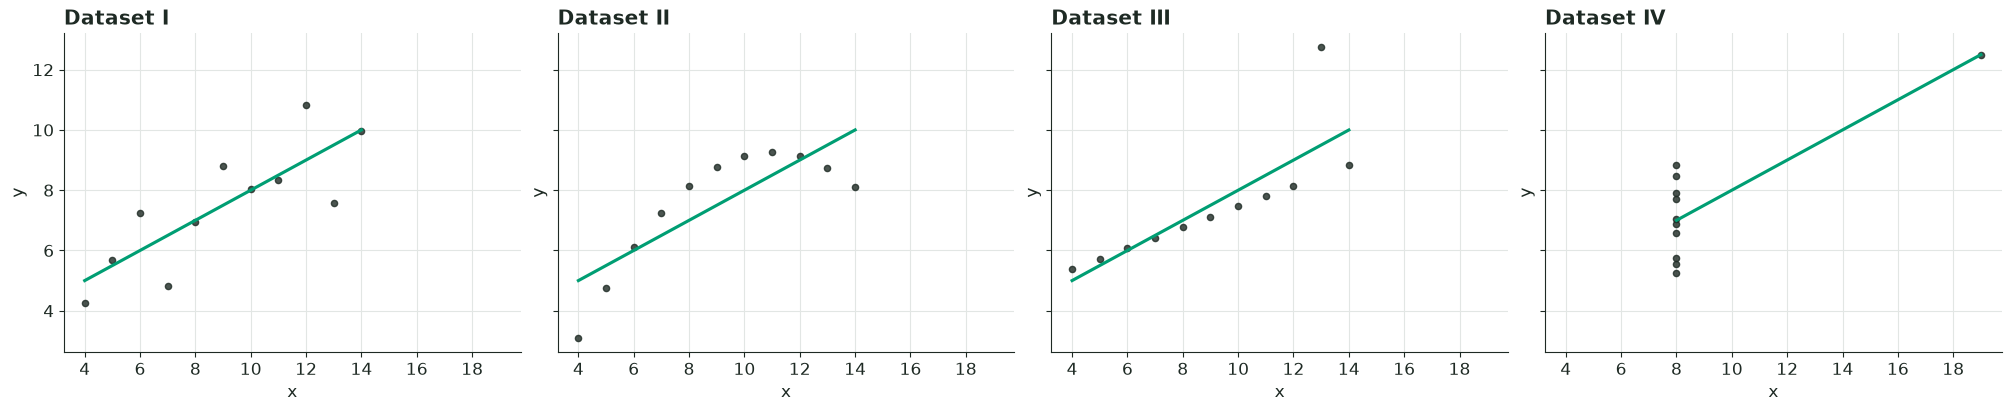

In [26]:
#Chartovive dole gi pravish so ova

#fig <- the whole image, the canvas
#axes <- lista na individualnite 4 charts
#plt.subplots(1, 4) <- pravi grid od charts so 1 row i 4 columns
#figsize <- goleminata na celata slika so site 4 chart vo inch x inch
#sharex=True, sharey=True <- gi pravi istite x i y axes za chartsot
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True, sharey=True)

for ax, (name, group) in zip(axes, groups): #<-groups tuka e od gore variable
    sns.regplot(
        group,
        x="x",
        y="y",
        ci=None,
        ax=ax,
        scatter_kws={"color": INK, "s": 20},
        line_kws={"color": PALETTE[2]},
    )
    ax.set_title(f"Dataset {name}")
plt.show()

The same summary describes a straight line with noise, a curve, a line with one outlier, and a vertical stack with one far point. The summary alone hides all of that.

### 9. Variable Types

The type of a column decides which summaries and which figures suit it. Each column of the listings is one of these types:

- **quantitative and continuous**, such as `price` and `area`, whose values can fall anywhere in a range,
- **quantitative and discrete**, such as `rooms`, `floor`, `floors`, `year_built`, `days_listed`, and `views`, whose values are whole numbers,
- **categorical and nominal**, such as `municipality`, `currency`, `seller`, `agency`, and the two-valued `elevator`, whose labels have no order, or
- **categorical and ordinal**, such as `condition`, whose labels have an order but no distance between them.

`listing_id` is an identifier. It is stored as a number, but it names a record rather than measuring anything, so its mean or its correlation means nothing. `price` mixes two currencies, which Section 13 handles.

A label column is stored as a category. An ordered category keeps the order of an ordinal variable, so it sorts and compares by meaning rather than alphabetically. The nullable `boolean` type keeps a missing elevator as a missing value, where a plain Boolean column would have no way to store it.

In [27]:
# print(df.dtypes)

for column in ["municipality", "currency", "seller", "agency"]:
    df[column] = df[column].astype("category")

df["condition"] = pd.Categorical(
    df["condition"],
    categories=["needs renovation", "good", "renovated", "new build"],
    ordered=True,
) #<-- need renovation e najlosho, new build e najdobro, a toa e poradi ordered=True

df["elevator"] = df["elevator"].astype("boolean")

df.dtypes

listing_id         int64
municipality    category
price              int64
currency        category
area             float64
rooms              int64
floor              int64
floors             int64
year_built         int64
condition       category
elevator         boolean
seller          category
agency          category
days_listed        int64
views              int64
dtype: object

An ordered category supports comparisons, so the next cell counts the listings that are renovated or newly built. A missing condition compares as false, so a listing without a condition is not counted.

In [28]:
(df["condition"] >= "renovated").sum() #<- I bidejki "condition" e ordered, mozes da gi sporeduvash vaka

np.int64(46)

### 10. The Shape of the Missingness

Counting the missing values says how many there are. Drawing them and crossing them against the other columns shows whether they follow a pattern, and a pattern suggests a reason that the data alone cannot confirm.

In [29]:
#<- df.insa() vrakja tabela so False kade ima vrednost i True kade ima 
# missing vrednost vo data frame-ot (None/Nan/<NA>). Vaka lici:
  #      price   condition   elevator   agency
  #0     False   False       False      True
  #1     False   True        False      False
  #2     False   False       True       True
  #...
#.sum() gi broi po kolona (vo Pyhton True=1, False=0) -> shto znaci deka sum e 
#brojot na koloni so missing vrednosti 

#[lambda counts: counts > 0] <- odlucuva koi koloni ke se prikazat otkoga
#broenjeto ke zavrshi

print(df.isna().sum())

print("\n")

print(df.isna().sum()[lambda counts: counts > 0])

listing_id       0
municipality     0
price            0
currency         0
area             0
rooms            0
floor            0
floors           0
year_built       0
condition       25
elevator        21
seller           0
agency          64
days_listed      0
views            0
dtype: int64


condition    25
elevator     21
agency       64
dtype: int64


The map below draws one column per listing, sorted from the oldest building on the left to the newest on the right, and marks each missing value.

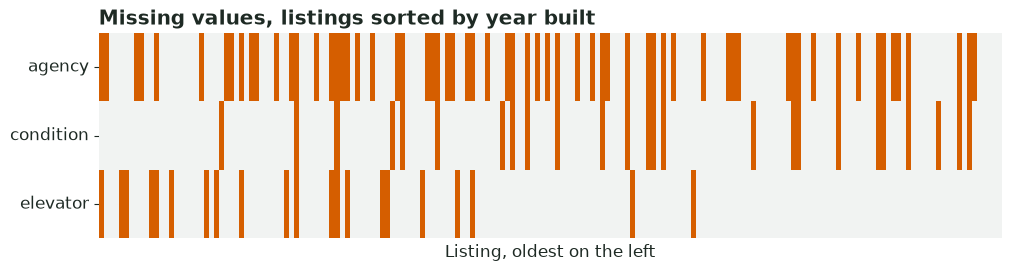

In [30]:
fig, ax = plt.subplots(figsize=(10, 2.6))

#missing_map <- varijabla shto ja sprema data-ta za heatmap chart-ot
  # df.sort_values("year_built") <- gi sortira od najstari do najnovi
  # [["agency", "contidion", "elevator"]] gi cuva ovie koloni
  # .insa() <- znaesh od gore shto pravi
  # .T <- ja flipnuva tabelata (rows become columns, columns become rows)

missing_map = df.sort_values("year_built")[["agency", "condition", "elevator"]].isna().T
sns.heatmap(
    missing_map, cbar=False, cmap=["#f1f3f2", PALETTE[1]], xticklabels=False, ax=ax
)
ax.set(
    title="Missing values, listings sorted by year built",
    xlabel="Listing, oldest on the left",
)
ax.tick_params(axis="y", rotation=0)
plt.show()

The `elevator` gaps gather among the oldest buildings, while the `agency` and `condition` gaps spread across all ages. Crossing each column with a candidate cause tests what the map suggests.

In [ ]:
# Cela poenta na ovoj kod tuka e da poznaesh dali nekoj trend ima:
# Konkretno primerov -> For the agency column, the obvious suspect 
# is: "maybe agency is missing because the flat is sold by a private 
# person, not an agency." -> Pa zatoa seller se razgleduva

pd.crosstab(df["seller"], df["agency"].isna().rename("agency missing"))

#Vaka se chita tabelata: 
#                     agency name present(False)   	agency name missing (True)
#   seller = agency	       116	                              0
#   seller = private         0	                              64

#Preku tabelata ja potvrdivme hipotezata gore.

agency missing,False,True
seller,,
agency,116,0
private,0,64


In [ ]:
# Poentata na ovaa proverka e DALI older buildings so pomalce katovi NEMAAT lift

old_and_low = ((df["year_built"] < 1980) & (df["floors"] <= 4)).rename(
    "built before 1980, four floors or fewer"
)
by_building = (
    df["elevator"]
    .isna() #<- True when elevator is missing
    .groupby(old_and_low) #<- podeli gi zgradite na 1.old_and_low i 2.site ostanati
    .agg(missing_elevators="sum", total_listings="size", share="mean")
    #.agg() ni dava vo sekoja kolona da napravime funkcija (sum, size, mean)
    # se napraveni vo primerov konkretno
    #sum ustvari gi sobira site TRUE stavki od .insa()
)
by_building.round(2)

,missing_elevators,total_listings,share
"built before 1980, four floors or fewer",,,
False,3,143,0.02
True,18,37,0.49


In [ ]:
#Probaj sam razberi go ova pred kolokvium za da povtorish

by_seller = (
    df["condition"]
    .isna()
    .groupby(df["seller"], observed=True)
    .agg(missing="sum", listings="size", share="mean")
)
by_seller.round(2)

,missing,listings,share
seller,,,
agency,5,116,0.04
private,20,64,0.31


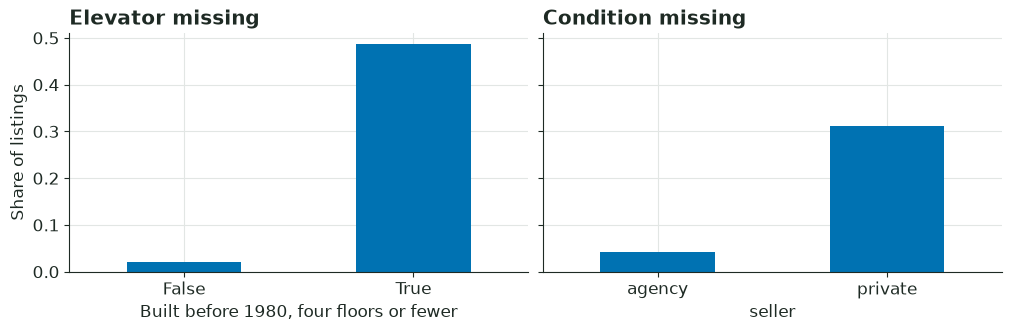

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)

#se zema procentot "mean" od dvete
by_building["share"].plot.bar(ax=axes[0], rot=0, title="Elevator missing") 
by_seller["share"].plot.bar(ax=axes[1], rot=0, title="Condition missing")

axes[0].set_xlabel("Built before 1980, four floors or fewer")
axes[0].set_ylabel("Share of listings")
plt.show()

Each column with gaps follows its own pattern:

- `agency` is missing for every private seller and for no agency listing, because the field does not apply to a private seller,
- `elevator` is missing for about half of the listings in buildings from before 1980 with four floors or fewer, and for very few of the others, and
- `condition` is missing far more often for private sellers than for agencies.

A missing value whose presence depends on another column is not a random gap. Exercise 3 presents the treatment of missing values, and the right treatment depends on which kind of gap it is.

### 11. Central Tendency and Spread

The mean and the median locate the centre of a column. The mean uses every value, so a few extreme values pull it, while the median is the middle value and ignores how far the extremes lie.

The range, the variance, the standard deviation, and the interquartile range measure the spread:

- the range is the distance from the smallest value to the largest,
- the variance is the mean squared distance from the mean, in squared units, and pandas divides by one less than the count, which gives the sample variance,
- the standard deviation is the square root of the variance, back in the units of the column, and
- the interquartile range is the distance from the first quartile to the third, which holds the middle half of the values.

In [69]:
def centre_and_spread(values: pd.Series) -> pd.Series:
    q1, q3 = values.quantile([0.25, 0.75])
    return pd.Series(
        {
            "mean": values.mean(),
            "median": values.median(),
            "range": values.max() - values.min(),
            "variance": values.var(),
            "std": values.std(),
            "Q1": q1,
            "Q2": values.median(),
            "Q3": q3,
            "IQR": q3 - q1,
        }
    )


pd.DataFrame(
    {
        "area": centre_and_spread(df["area"]), 
        "views": centre_and_spread(df["views"])
    }
).round(1)

,area,views
mean,68.4,845.6
median,65.8,439.5
range,89.0,6809.0
variance,494.9,1052049.0
std,22.2,1025.7
Q1,52.8,214.0
Q2,65.8,439.5
Q3,86.0,1057.2
IQR,33.2,843.2


For `area` the mean and the median nearly agree. For `views` the mean lies far above the median and the standard deviation exceeds the mean, which points to a long right tail: a few listings with very many views pull the mean and the standard deviation up. For such a column the median and the interquartile range describe a typical listing better.

The mode is the most frequent value. It applies to a discrete column and to a label column alike, where the mean and the median do not apply to labels. `mode()` returns a series, because several values can tie for the most frequent, so the cell takes the first one.

In [ ]:
#.mode() <- vrakja moda (prosek)


df["rooms"].mode().iloc[0], df["municipality"].mode().iloc[0]

(np.int64(2), 'Карпош')

### 12. Histograms and Box Plots

A histogram divides the range of a column into bins and counts the values in each bin, so it shows the shape of a distribution. Its bin count changes what it shows. Too few bins hide the shape, and too many turn it into noise.

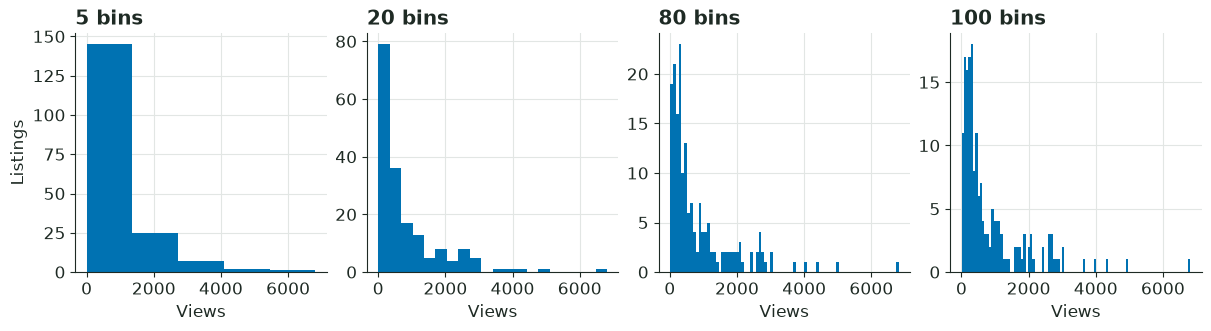

In [96]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=False)
for ax, bins in zip(axes, [5, 20, 80, 100]):
    ax.hist(df["views"], bins=bins)
    ax.set(title=f"{bins} bins", xlabel="Views")
axes[0].set_ylabel("Listings")
plt.show()

A box plot draws the same column more compactly. The box spans the interquartile range, and the line inside it is the median. The whiskers reach the furthest values that lie within 1.5 interquartile ranges of the box, and each value beyond them is drawn as a separate point.

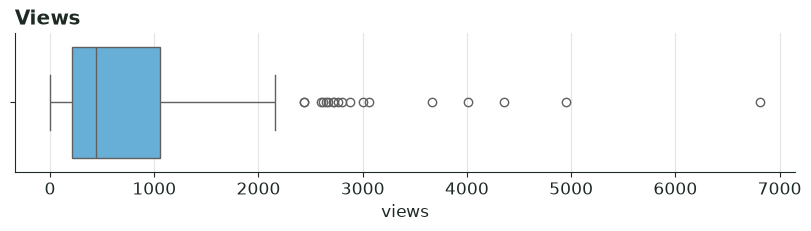

In [93]:
fig, ax = plt.subplots(figsize=(8, 2.2))
sns.boxplot(df, x="views", ax=ax, color=PALETTE[5])
ax.set_title("Views")
plt.show()

The skewness coefficient summarizes the asymmetry in one number. It is close to zero for a symmetric distribution, positive when the long tail lies on the right, and negative when it lies on the left. A value beyond 1 in either direction marks a strongly skewed column.

In [ ]:
df[["area", "views"]].skew().round(2) #.skew() <-

area     0.13
views    2.41
dtype: float64

`area` is nearly symmetric, and `views` is strongly skewed to the right, as both figures show.

### 13. A Column That Mixes Units

`price` holds amounts in two currencies, EUR and MKD, and a flat priced in MKD carries a number about sixty times larger than the same flat priced in EUR. A summary of the pooled column mixes two units, so the column is compared within each currency before it is converted.

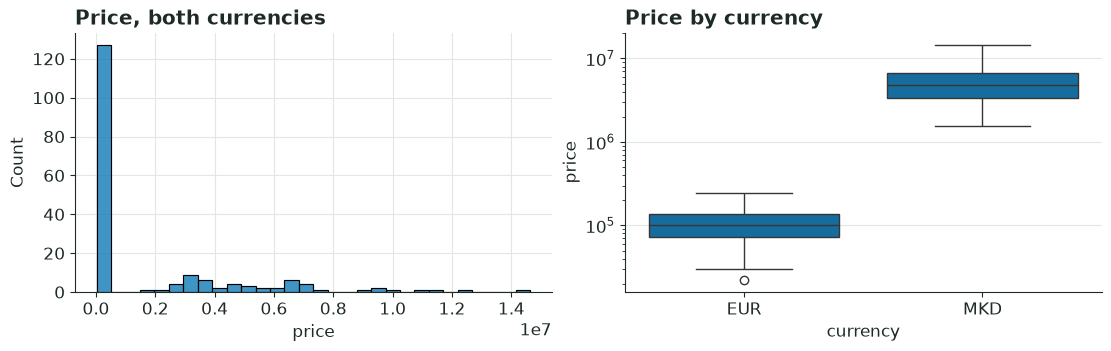

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(df, x="price", bins=30, ax=axes[0])
axes[0].set_title("Price, both currencies")
sns.boxplot(df, x="currency", y="price", ax=axes[1], log_scale=True)
axes[1].set_title("Price by currency")
plt.show()

In [ ]:
#pooled <- statistika za site prices zaedno
#i dole si ima posebno za EUR i posebno za MKD statistiki

pooled = pd.DataFrame(
    {
        "count": [len(df)],
        "median": [df["price"].median()],
        "skew": [df["price"].skew()],
    },
    index=pd.Index(["pooled"], name="currency"),
)
by_currency = df.groupby("currency", observed=True)["price"].agg(
    ["count", "median", "skew"]
)
pd.concat([pooled, by_currency]).round(2)

,count,median,skew
currency,,,
pooled,180,126000.0,1.96
EUR,127,100000.0,0.67
MKD,53,4830000.0,1.20


Pooled, the column is strongly skewed, because the MKD prices form a second cluster far to the right of the EUR prices. Within each currency the skew is smaller, so much of the pooled skew comes from mixing the units rather than from the prices themselves.

Converting every price to EUR at a fixed rate makes the column comparable, and the price per square metre makes flats of different sizes comparable.

In [119]:
MKD_PER_EUR = 61.5
df["price_eur"] = df["price"].where(df["currency"] == "EUR", df["price"] / MKD_PER_EUR)
df["eur_per_m2"] = df["price_eur"] / df["area"]
df[["price_eur", "eur_per_m2"]].agg(["median", "skew"]).round(2)

,price_eur,eur_per_m2
median,95500.00,1467.38
skew,0.78,0.45


After the conversion, both columns are only moderately skewed.

### 14. Counts of a Category

A categorical column is described by the count and the share of each label, and drawn as a bar plot. A nominal variable is sorted by count, so the bars read from the most common label to the least common, and an ordinal one keeps its own order.

In [130]:
counts = df["municipality"].value_counts()

print("counts: \n", counts)
print("\n")

pd.DataFrame({"count": counts, "share": (counts / counts.sum()).round(3)})

counts: 
 municipality
Карпош          37
Аеродром        36
Центар          26
Гази Баба       22
Бутел           17
Кисела Вода     15
Ѓорче Петров    14
Чаир            13
Name: count, dtype: int64




,count,share
municipality,,
Карпош,37,0.206
Аеродром,36,0.200
Центар,26,0.144
Гази Баба,22,0.122
Бутел,17,0.094
Кисела Вода,15,0.083
Ѓорче Петров,14,0.078
Чаир,13,0.072


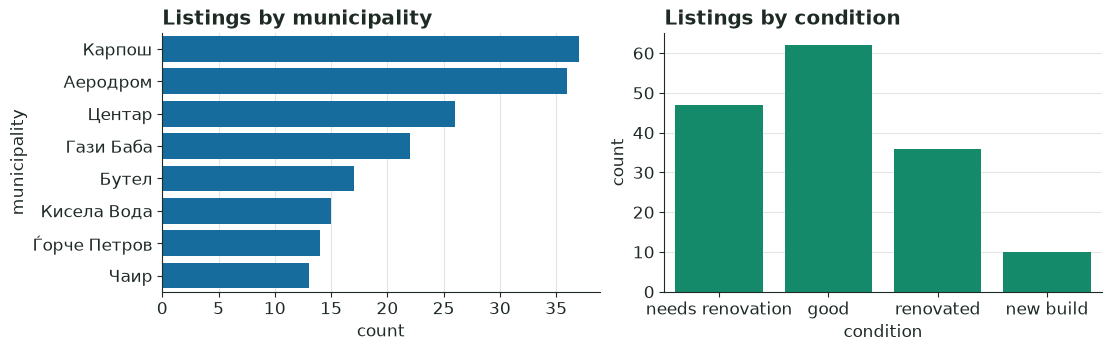

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.countplot(df, y="municipality", order=counts.index, ax=axes[0], color=PALETTE[0])
axes[0].set_title("Listings by municipality")
sns.countplot(df, x="condition", ax=axes[1], color=PALETTE[2])
axes[1].set_title("Listings by condition")
plt.show()

The condition plot counts only the listings that have a condition, so its bars sum to fewer listings than the data frame holds.

In [136]:
df["condition"].notna().sum(), len(df)

(np.int64(155), 180)

### 15. Relationships and Correlation

A scatter plot shows how two quantitative columns move together, with one point per listing.

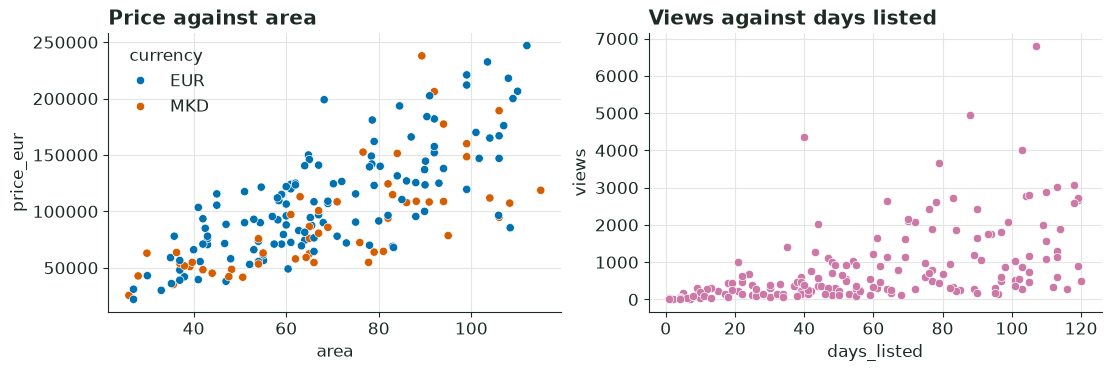

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.scatterplot(df, x="area", y="price_eur", hue="currency", ax=axes[0])
axes[0].set_title("Price against area")
sns.scatterplot(df, x="days_listed", y="views", ax=axes[1], color=PALETTE[3])
axes[1].set_title("Views against days listed")
plt.show()

A correlation coefficient summarizes such a relationship in one number between −1 and 1:

- the Pearson coefficient measures how close the points lie to a straight line, and
- the Spearman coefficient is the Pearson coefficient of the ranks, so it measures how close the relationship is to monotonic, meaning that one column rises whenever the other does, whatever the shape.

A rank does not grow with the distance of an extreme value, so the Spearman coefficient is less sensitive to a long tail.

In [141]:
pairs = [("area", "price_eur"), ("days_listed", "views"), ("eur_per_m2", "views")]
pd.DataFrame(
    {
        "pearson": [df[a].corr(df[b]) for a, b in pairs],
        "spearman": [df[a].corr(df[b], method="spearman") for a, b in pairs],
    },
    index=[f"{a} and {b}" for a, b in pairs],
).round(2)

,pearson,spearman
area and price_eur,0.73,0.73
days_listed and views,0.51,0.64
eur_per_m2 and views,-0.44,-0.49


For `area` and `price_eur` the two coefficients agree. For `days_listed` and `views` the Spearman coefficient is the larger one, because the long tail of `views` weakens the straight-line fit more than it weakens the order.

The heatmap below shows the Spearman coefficient of every pair of numeric columns. `listing_id` is left out, because it is an identifier.

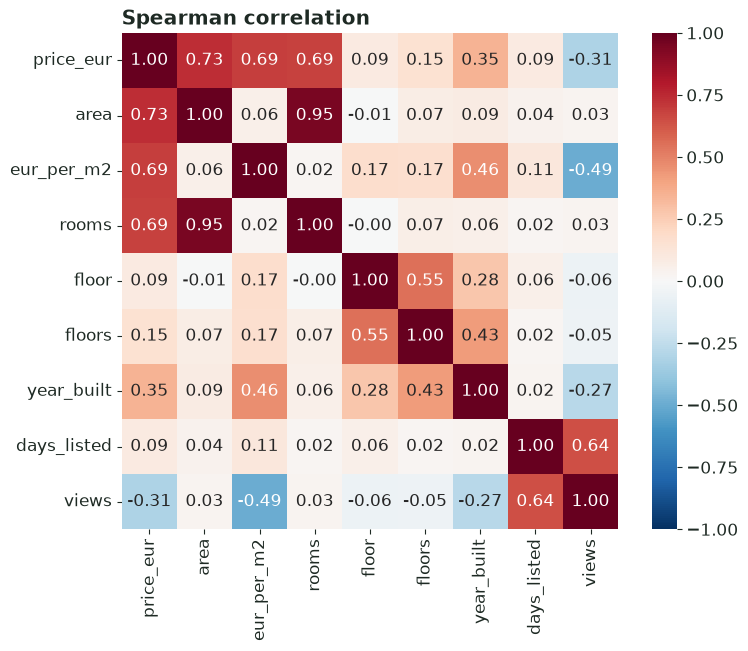

In [143]:
numeric = [
    "price_eur",
    "area",
    "eur_per_m2",
    "rooms",
    "floor",
    "floors",
    "year_built",
    "days_listed",
    "views",
]
fig, ax = plt.subplots(figsize=(8, 6.4))
sns.heatmap(
    df[numeric].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title("Spearman correlation")
plt.show()

Correlation is not causation. A correlation says that two columns move together, but not which one moves the other, or whether a third factor moves both:

- views and days listed correlate, and here the mechanism is known, because views accumulate while a listing stays online, and
- views and the price per square metre correlate negatively, which fits the explanation that buyers look more at cheaper flats, but the data alone cannot confirm that explanation or rule out another one.

### 16. Grouping and Aggregation

Grouping splits the rows by a label, aggregation reduces each group to a few numbers, and sorting and pivoting arrange the result to answer a question. Here the question is whether the market index of the portal, which it describes as the mean price per square metre with MKD prices converted to EUR, agrees with the listings.

In [147]:
by_municipality = (
    df.groupby("municipality", observed=True)
    .agg(
        listings=("listing_id", "size"),
        mean_eur_per_m2=("eur_per_m2", "mean"),
        median_eur_per_m2=("eur_per_m2", "median"),
    )
    .round(0)
    .reset_index()
    .astype({"municipality": str})
    .merge(market_index, on="municipality", validate="one_to_one")
    .sort_values("mean_eur_per_m2", ascending=False)
)
by_municipality

,municipality,listings,mean_eur_per_m2,median_eur_per_m2,portal_eur_per_m2
6,Центар,26,1977.0,1934.0,1977
4,Карпош,37,1916.0,1877.0,1916
1,Аеродром,36,1530.0,1458.0,1530
5,Кисела Вода,15,1330.0,1297.0,1330
3,Гази Баба,22,1218.0,1205.0,1218
7,Чаир,13,1092.0,1025.0,1092
0,Ѓорче Петров,14,1064.0,1003.0,1064
2,Бутел,17,1042.0,1009.0,1042


The mean computed from the listings reproduces the index of the portal in every municipality. The median lies below the mean in every municipality, because a few expensive flats pull the mean up.

A pivot table crosses two labels. Each cell below holds the number of listings for one municipality and one condition.

In [151]:
cell_counts = df.pivot_table(
    index="municipality",
    columns="condition",
    values="listing_id",
    aggfunc="size",
    observed=True,
    fill_value=0,
).loc[by_municipality["municipality"]]
cell_counts

condition,needs renovation,good,renovated,new build
municipality,,,,
Центар,8,10,2,0
Карпош,6,15,6,3
Аеродром,9,11,7,2
Кисела Вода,6,4,2,2
Гази Баба,3,10,8,1
Чаир,2,3,6,1
Ѓорче Петров,8,0,4,0
Бутел,5,9,1,1


A median built from one or two listings is as noisy as its count suggests, so the heatmap of the median price per square metre leaves blank every cell with fewer than three listings.

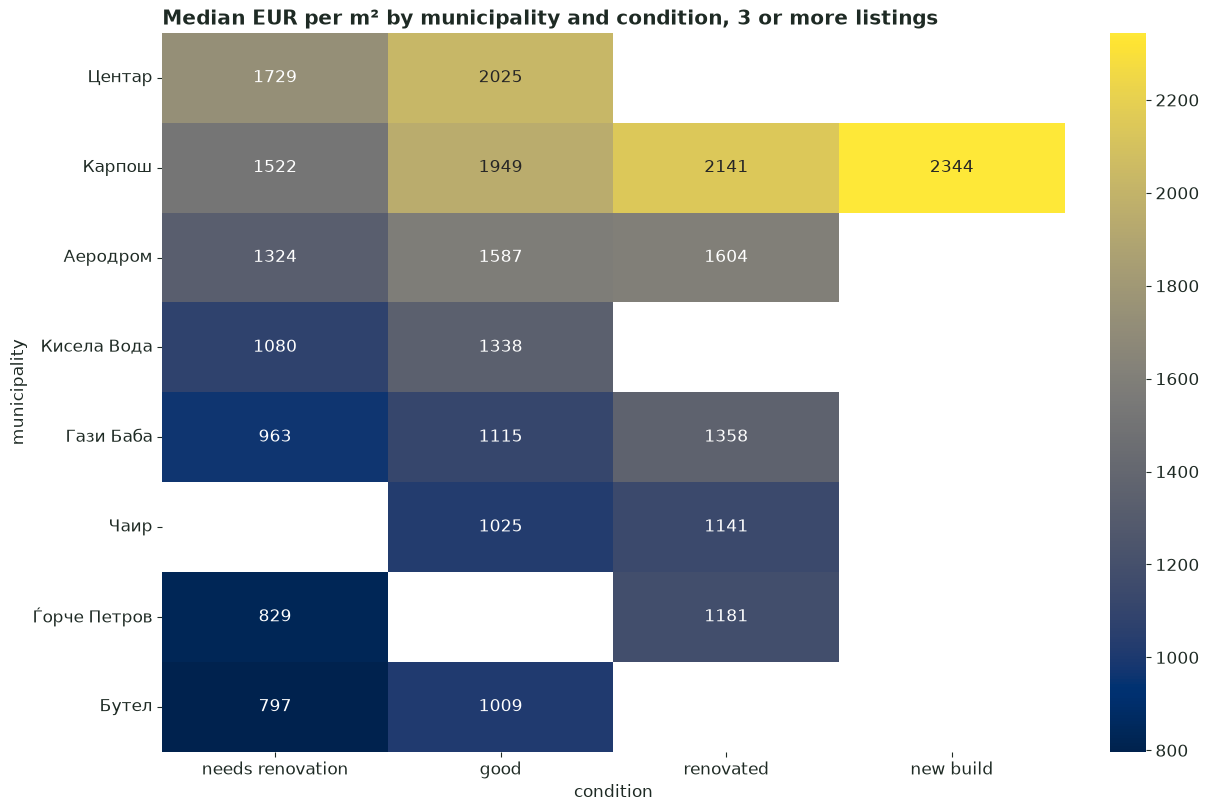

In [154]:
MIN_LISTINGS = 3
pivot = df.pivot_table(
    index="municipality",
    columns="condition",
    values="eur_per_m2",
    aggfunc="median",
    observed=True,
).loc[cell_counts.index, cell_counts.columns]
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    pivot, mask=cell_counts < MIN_LISTINGS, annot=True, fmt=".0f", cmap="cividis", ax=ax
)
ax.set_title(
    f"Median EUR per m² by municipality and condition, {MIN_LISTINGS} or more listings"
)
ax.grid(False)
plt.show()

In [153]:
server.shutdown()